In [1]:
import cobra
import sys
sys.path.append('/home/nathan/thermo_flux')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from thermo_flux.io import helper_load as hl

import os


import seaborn as sns
sys.path.append(os.path.abspath('../3_src/'))

import analysis.io_func as io_func


## in this notebook we perform VA on the stoichiometrci model then compare the flux range reductions (relative range reductions : rangeSM- range TSM/rangeSM) 
where range = abs(ub-lb) for each reaction 
### also get n0 of irreversible reactions in stoichiometric model

In [2]:

BASE_FOLDERNAME=f'{os.path.expanduser("~/")}/PhD/04.Computational/202601_13C'

INPUT_FOLDER=f"{BASE_FOLDERNAME}/1_data/b_processed_files/"
OUTPUT_FOLDER = f"{BASE_FOLDERNAME}/4_results/a_fluxspace/"
SYNDATA_FOLDER = f"{BASE_FOLDERNAME}/1_data/c_synthetic_data/"

OUTPUT_FOLDER_PLOTS = f"Figures/"

OUTPUT_FILENAME=f'202601_13C_tf01'
ADD='nomet'

In [3]:
# Import general configs:
palette ,cfg =io_func.import_plotconfigs()

In [4]:
#
xiang_data=pd.read_excel(f'{INPUT_FOLDER}yeast_data_xiang_metabolites.xlsx',sheet_name='Assembly for Joana',index_col=1,header=[0,1])
display(xiang_data.head())
xiang_data=xiang_data.iloc[:,:-2].copy()
xiang_data=xiang_data.drop(index='not in the model')
#when cells have a < in it, replace it with nothing
##we need a value not a upper bound : we'll fit the treshold identified by Xiang
#the std will be higher than the value : 0.01 mmol/L
xiang_data.replace('<', '', regex=True, inplace=True)
xiang_data.replace(np.nan,0.01,inplace=True)
#there are 5 metabolites in dx that are not in WT/tm6 , and 9 in WT/tm6 that are not in dx

TM6_df=pd.DataFrame(index=pd.MultiIndex.from_product([['TM6'],xiang_data.index.tolist()]),columns=['mean','sd'])
TM6_df['mean']=xiang_data[('TM6','average')].values.astype(float)
TM6_df['sd']=xiang_data[('TM6','stdev')].values.astype(float)
#same for WT
WT_df=pd.DataFrame(index=pd.MultiIndex.from_product([['WT'],xiang_data.index.tolist()]),columns=['mean','sd'])
WT_df['mean']=xiang_data[('WT','average')].values.astype(float)
WT_df['sd']=xiang_data[('WT','stdev')].values.astype(float)
#concatenate the two dataframes and metabolite data
metabolite_data=pd.concat([TM6_df,WT_df])
metabolite_data.head()

# load regression data
reg_data = hl.excel_to_df(f'{INPUT_FOLDER}extended_regressiondata_Canelas_Xiang_yeast.xlsx')
reg_data.keys()

reg_data['dvmeas'] = reg_data['dvmeas'].reset_index()
reg_data['dvmeas'].columns = ['cond','rxn','mean_sd','Value']
reg_data['dvmeas'] = reg_data['dvmeas'].replace({'biomass':'biomass_EX'})
reg_data['dvmeas'] = reg_data['dvmeas'].pivot(index=['cond', 'rxn'], columns='mean_sd', values='Value').rename_axis(None, axis=1)

### then create usual df with data


metabolite_data.drop(['gtp','cdp','ctp','gdp', 'nad','nadh', 'nadp', 'nadph'],level=1, axis=0, inplace=True) # ignore the NAD(P)H data as these are defined as ratios 
volume_data = pd.DataFrame({'WT':{'c':0.95, 'm':0.05}, 'TM6':{'c':0.90, 'm':0.1}}).T #specify the volume fractions for each condition

flux_data = reg_data['dvmeas']
flux_data=flux_data.loc[['WT','TM6']]
flux_data.drop(['o2_EX'],level=1, axis=0, inplace=True) #ignore the o2 flux data
# flux_data#.to_csv('../processed_files/exflux_data.csv')
conditions=flux_data.index.get_level_values(0).unique()
print(conditions)

flux_data#.head()

Unnamed: 0_level_0       TM6                  WT                    \
GAMS name       DELFT abbrev   average     stdev   average     stdev stdev.1   
ala-L                    Ala  2.077416  0.682723  2.663769  0.207449     NaN   
gly                      Gly  0.486339  0.115566  1.658099  0.036913     NaN   
val-L                    Val  0.923879  0.170710  1.494332  0.009641     NaN   
leu-L                    Leu  0.143934  0.023261  0.145673  0.007090     NaN   
ile-L                    Ile   0.19462  0.030614  0.387366  0.014147     NaN   

                                 
GAMS name in mmol/L cell volume  
ala-L                       NaN  
gly                         NaN  
val-L                       NaN  
leu-L                       NaN  
ile-L                       NaN

Index(['WT', 'TM6'], dtype='object', name='cond')


mean        sd
cond rxn                            
WT   ac_EX        0.259709  0.012362
     biomass_EX   0.349297  0.004761
     co2tot_EX   23.917635  0.230015
     etoh_EX     23.717417  0.419155
     glc-D_EX   -15.031675  0.257198
     glyc_EX      1.788621  0.041279
     pyr_EX       0.196533  0.004077
TM6  ac_EX        0.083514  0.021615
     biomass_EX   0.250774  0.002863
     co2tot_EX    8.247865  0.286968
     etoh_EX      0.120855  0.036590
     glc-D_EX    -3.153914  0.074257
     glyc_EX      0.053192  0.023867
     pyr_EX       0.012296  0.004983

load VA results from blocked EXG

In [5]:
VA_fluxes_nomet=[]
for condi in ['WT','TM6']:
    VA_fluxes_nomet.append(pd.read_csv(f'{OUTPUT_FOLDER}/{OUTPUT_FILENAME}_{ADD}_flux_bounds_{condi}.csv',index_col=0))

df_VA_fluxes_nomet=pd.concat(VA_fluxes_nomet,keys=['WT', 'TM6'])


## first, we look at reaction reversibilities in tmodel 

In [6]:

def get_reversibilities(VA_fluxes_all,cond=None):
    if cond :
        check_rev=VA_fluxes_all.loc[cond].copy()
    else : 
        check_rev=VA_fluxes_all.copy()
    check_rev[abs(check_rev)<1e-6]=0
    check_rev['Reversibility']='0'
    for i,row in check_rev.iterrows():
        if abs(row['lb'])<1e-6 and abs(row['ub'])<1e-6:
            pass
            # check_rev.loc[i,'Reversibility']='Blocked'
        elif row['lb']>=0 :
            check_rev.loc[i,'Reversibility']='Forward'
        elif row['ub']<=0:
            check_rev.loc[i,'Reversibility']='Backward'
        else:
            check_rev.loc[i,'Reversibility']='Reversible'
        
    counts= check_rev['Reversibility'].value_counts().to_dict()
    return check_rev,[counts['Forward'],counts['Backward'],counts['Reversible']]#,counts['Blocked']]

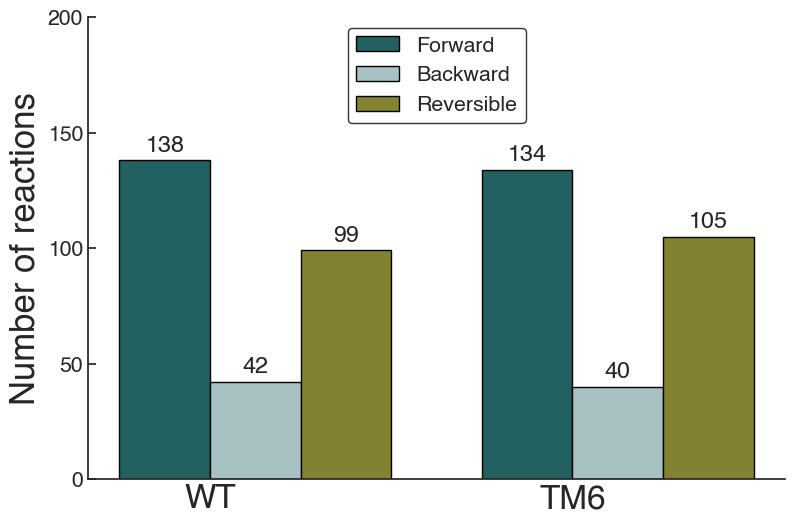

In [7]:
## now the pltos of TF and GAMs on the same plto
# Bar width and positions
bar_width = 0.25
index = np.arange(2) 
# Plot the grouped bar chart
fig, ax = plt.subplots(figsize=(9, 6))
(_,size_WT),(_,size_TM6)=get_reversibilities(df_VA_fluxes_nomet,'WT') ,get_reversibilities(df_VA_fluxes_nomet,'TM6')
labels=['Forward','Backward','Reversible']

# Plot the bars for each category in both groups
multiplier = 0
for i, category in enumerate(labels):
    offset = bar_width * multiplier
    rects1 = ax.bar(index - bar_width/2 + offset, [size_WT[i], size_TM6[i]], bar_width, label=category,edgecolor='black')
    ax.bar_label(rects1, padding=3)
    multiplier += 1

# Add labels, title, and custom x-axis tick labels
ax.set_ylabel('Number of reactions')
# ax.set_title('Distribution of Reaction Types in GAMS and TF')
ax.set_xticks(np.arange(2) )
ax.set_xticklabels(['WT', 'TM6'],fontsize=24)
ax.legend(loc='upper center',edgecolor='black')
ax.set_ylim(0, 200)  # Adjust y-axis limit
plt.locator_params(axis='y', nbins=4)
# plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/WTvTM6_{ADD}_tmodel_rxn_reversibilities_fromv.png',dpi=300,bbox_inches='tight')
# plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/WTvTM6_{ADD}_tmodel_rxn_reversibilities_fromv.svg',dpi=300,bbox_inches='tight')

In [8]:
df_WT,_=get_reversibilities(df_VA_fluxes_nomet,'WT')
df_TM6,_=get_reversibilities(df_VA_fluxes_nomet,'TM6')
list_diff_rxn=[i for i in df_TM6.index if df_TM6.loc[i,'Reversibility']!=df_WT.loc[i,'Reversibility']]
df_WT.loc[list_diff_rxn],df_TM6.loc[list_diff_rxn]
list_same=[i for i in df_TM6.index if df_TM6.loc[i,'Reversibility']==df_WT.loc[i,'Reversibility']=='Reversible']
print('wt',df_WT['Reversibility'].value_counts(),len(list_same),'tm6',df_TM6['Reversibility'].value_counts())

wt Reversibility
Forward       138
Reversible     99
Backward       42
0               3
Name: count, dtype: int64 99 tm6 Reversibility
Forward       134
Reversible    105
Backward       40
0               3
Name: count, dtype: int64


## now load SM model and do variability analysis

In [9]:
### load model that we saved
model=cobra.io.read_sbml_model(f'{INPUT_FOLDER}/cobra_roundp3_ymodel.xml')
model

Set parameter Username
Set parameter LicenseID to value 2749904
Set parameter GURO_PAR_DUMP to value 1
Read parameters from file gurobi.env
Academic license - for non-commercial use only - expires 2026-12-04


Name,yeast
Memory address,72fa02cca920
Number of metabolites,232
Number of reactions,282
Number of genes,0
Number of groups,0
Objective expression,1.0*biomass_EX - 1.0*biomass_EX_reverse_22313
Compartments,"c, m, e"


In [10]:
from cobra.flux_analysis import flux_variability_analysis
CI=3
flux_data['lb'] = flux_data['mean'] - CI*abs(flux_data['sd'])
flux_data['ub'] = flux_data['mean'] + CI*abs(flux_data['sd'])

cond='WT'
def load_bounds_fva(cond,flux_data)->pd.DataFrame:
    model=cobra.io.read_sbml_model(f'{INPUT_FOLDER}/cobra_roundp3_ymodel.xml') ##load model to reset bound## is ok fast
    for rxn_id,row in flux_data.loc[cond].iterrows() :
        lb = row['lb']
        ub = row['ub']
        model.reactions.get_by_id(rxn_id).lower_bound=lb
        model.reactions.get_by_id(rxn_id).upper_bound=ub
        print(rxn_id,lb,ub)

    return flux_variability_analysis(model).rename(columns={'minimum':'lb','maximum':'ub'})
load_bounds_fva('WT',flux_data)
# print(get_reversibilities(load_bounds_fva('WT',flux_data)))
fva_rev_wt=get_reversibilities(load_bounds_fva('WT',flux_data))

ac_EX 0.22262328325827713 0.2967943084776869
biomass_EX 0.33501304000000004 0.36358096
co2tot_EX 23.227588831459514 24.607681497841483
etoh_EX 22.459951652753162 24.974883060016836
glc-D_EX -15.80326984228146 -14.260080041201538
glyc_EX 1.6647846913016933 1.9124567443471667
pyr_EX 0.184302735339106 0.20876327822078003
ac_EX 0.22262328325827713 0.2967943084776869
biomass_EX 0.33501304000000004 0.36358096
co2tot_EX 23.227588831459514 24.607681497841483
etoh_EX 22.459951652753162 24.974883060016836
glc-D_EX -15.80326984228146 -14.260080041201538
glyc_EX 1.6647846913016933 1.9124567443471667
pyr_EX 0.184302735339106 0.20876327822078003


In [11]:
# print(get_reversibilities(load_bounds_fva('TM6',flux_data)))
fva_rev_tm6=get_reversibilities(load_bounds_fva('TM6',flux_data))
list_same_SM=[i for i in fva_rev_tm6[0].index if fva_rev_tm6[0].loc[i,'Reversibility']==fva_rev_wt[0].loc[i,'Reversibility']=='Reversible']
print(len(list_same_SM),fva_rev_wt[0]['Reversibility'].value_counts(),fva_rev_tm6[0]['Reversibility'].value_counts())

ac_EX 0.0186684916037224 0.1483586141612614
biomass_EX 0.24218566 0.25936234
co2tot_EX 7.386962001501643 9.108768852657576
etoh_EX 0.011085532499868295 0.2306242564330797
glc-D_EX -3.3766853412261253 -2.931142839609295
glyc_EX -0.01841016565909321 0.12479367988471801
pyr_EX -0.00265377506542434 0.02724601731823794
161 Reversibility
Reversible    166
Forward        93
Backward       23
Name: count, dtype: int64 Reversibility
Reversible    164
Forward        94
Backward       24
Name: count, dtype: int64


## first irreversible reactions 

In [12]:
fva_SM_tm6,_=get_reversibilities(load_bounds_fva('TM6',flux_data))
fva_SM_WT,_=get_reversibilities(load_bounds_fva('WT',flux_data))

ac_EX 0.0186684916037224 0.1483586141612614
biomass_EX 0.24218566 0.25936234
co2tot_EX 7.386962001501643 9.108768852657576
etoh_EX 0.011085532499868295 0.2306242564330797
glc-D_EX -3.3766853412261253 -2.931142839609295
glyc_EX -0.01841016565909321 0.12479367988471801
pyr_EX -0.00265377506542434 0.02724601731823794
ac_EX 0.22262328325827713 0.2967943084776869
biomass_EX 0.33501304000000004 0.36358096
co2tot_EX 23.227588831459514 24.607681497841483
etoh_EX 22.459951652753162 24.974883060016836
glc-D_EX -15.80326984228146 -14.260080041201538
glyc_EX 1.6647846913016933 1.9124567443471667
pyr_EX 0.184302735339106 0.20876327822078003


## now compare flux ranges from SM with TSM

In [13]:

def get_relative_ranges(cond,VA_fluxes_all,fva_sm_df):
    #mkae a func that compute ranges

    def get_ranges(row):
        return abs(row['ub']-row['lb'])#/abs(row['ub']) if row['ub']!=0 else 0
    ##make a dataframe tos tore ranges SM vs TSM
    df_flux_ranges=pd.DataFrame(index=[r.id for r in model.reactions])
    for i,row in VA_fluxes_all.loc[cond].iterrows():
        df_flux_ranges.loc[i,'TSM']=get_ranges(row)
    for i, row in fva_sm_df.iterrows():
        df_flux_ranges.loc[i,'SM']=get_ranges(row)
    df_flux_ranges[abs(df_flux_ranges)<1e-6]=0
    df_flux_ranges['Relative difference']=(df_flux_ranges['SM']-df_flux_ranges['TSM'])/df_flux_ranges['SM'] 
    df_flux_ranges[abs(df_flux_ranges)<1e-6]=0

    df_flux_ranges=df_flux_ranges.replace(-np.inf,0).replace(np.inf,0)
    return df_flux_ranges.loc[[r.id for r in model.reactions if r.id not in flux_data.loc[cond].index]]

In [14]:
df_plot_wt=get_relative_ranges('WT',df_VA_fluxes_nomet,fva_SM_WT)
df_plot_TM6=get_relative_ranges('TM6',df_VA_fluxes_nomet,fva_SM_tm6)
# df_plot.mean()

# df_rangereduc_final_wt=get_relative_ranges('WT',VA_fluxes_fullmodel,fva_SM_WT)
# df_rangereduc_final_tm6=get_relative_ranges('TM6',VA_fluxes_fullmodel,fva_SM_tm6)

In [15]:
# #### in this cell i get "Flux ranges obtained in the (TSM, P.) model are reduced by about 60\% compared to the SM model, 
# # and the addition of actual metabolome data further constrained the flux ranges by 5\%, with different effects for the two strains\ref{fig2}"
# fig,ax=plt.subplots(2,1,sharey=True,sharex=True)
# ax[0].hist(df_plot_wt['Relative difference'],bins=10,alpha=1,edgecolor='black',histtype='step',linestyle='--',linewidth=2)
# ax[0].hist(df_rangereduc_final_wt['Relative difference'],bins=10,label='WT',alpha=1,edgecolor='black',color=sns.color_palette(palette)[0])
# ##second ax
# ax[1].hist(df_plot_TM6['Relative difference'],bins=10,edgecolor='black',histtype='step',linestyle='--',linewidth=2)
# ax[1].hist(df_rangereduc_final_tm6['Relative difference'],bins=10,label='TM6',edgecolor='black')

# ax[0].legend(edgecolor='white'),ax[1].legend(edgecolor='white')
# ax[1].set_ylabel('Number of reactions',fontsize=20)
# ax[1].set_xlabel('Relative flux range reduction (SM to TSM)',fontsize=18)
# ax[0].set_ylim(0,160)
# ##add vertical lines for means 
# ax[0].vlines(df_plot_wt['Relative difference'].mean(),ymin=0,ymax=250,linestyle=':',color='gray')
# ax[0].vlines(df_rangereduc_final_wt['Relative difference'].mean(),ymin=0,ymax=250,**cfg['settings_diagonal'],)

# ax[1].vlines(df_plot_TM6['Relative difference'].mean(),ymin=0,ymax=250,linestyle=':',color='gray')
# ax[1].vlines(df_rangereduc_final_tm6['Relative difference'].mean(),ymin=0,ymax=250,**cfg['settings_diagonal'],)
# ##set 4 yticks
# plt.locator_params(axis='y', nbins=4)
# print('sm to tsm p',df_plot_wt['Relative difference'].mean(),df_plot_TM6['Relative difference'].mean())
# print('sm to tsm p+m',df_rangereduc_final_wt['Relative difference'].mean(),df_rangereduc_final_tm6['Relative difference'].mean())
# # plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/SM_TSM_{ADD}_vrange_reduction.png',dpi=300,bbox_inches='tight')
# # plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/SM_TSM_{ADD}_vrange_reduction.svg',dpi=300,bbox_inches='tight')


In [16]:
# ,## just plot wt
# fig,ax= plt.subplots()
# # ax.hist(df_plot_wt['Relative difference'],bins=10,edgecolor='black',color='grey',alpha=0.7,align='left',rwidth=0.8)
# # ax.hist(df_rangereduc_final_wt['Relative difference'],bins=10,label='WT',edgecolor='black',color='black',alpha=0.7,align='mid',rwidth=0.8)
# pd.set_option('display.max_rows', None)
# df_plot_wt.replace(np.nan,0,inplace=True)
# df_rangereduc_final_wt.replace(np.nan,0,inplace=True)
# hist_andplot(df_plot_wt,'Relative difference',ax,6,large=0.4,offset=-0.1)
# hist_andplot(df_rangereduc_final_wt,'Relative difference',ax,6,large=0.4,offset=-0.05)

# #[df_plot_wt['TSM']==np.nan]

## compare with TSM physio and emtabolome data

In [17]:
VA_fluxes_full=[]
for condi in ['WT','TM6']:
    VA_fluxes_full.append(pd.read_csv(f'{OUTPUT_FOLDER}/{OUTPUT_FILENAME}_flux_bounds_{condi}.csv',index_col=0))

df_VA_fluxes_full=pd.concat(VA_fluxes_full,keys=['WT', 'TM6'])


In [18]:
## irr rxn 

rev_vafluxfullwt=get_reversibilities(df_VA_fluxes_full,'WT')[0]
rev_vafluxfulltm6=get_reversibilities(df_VA_fluxes_full,'TM6')[0]

In [19]:
rev_vafluxfulltm6['Reversibility'].value_counts()
# 282-92
# rev_vafluxfullwt['Reversibility'].value_counts()


Reversibility
Forward       143
Reversible     92
Backward       35
0              12
Name: count, dtype: int64

In [20]:
### which reversible reacitons are the same in WT and TM 6
list_same_TSM=[i for i in rev_vafluxfullwt.index if rev_vafluxfullwt.loc[i,'Reversibility']==rev_vafluxfulltm6.loc[i,'Reversibility']=='Reversible']
list_same_TSM_opp=[
    i for i in rev_vafluxfulltm6.index
      if rev_vafluxfulltm6.loc[i,'Reversibility']!=
      rev_vafluxfullwt.loc[i,'Reversibility'] ]
print(len(list_same_TSM))#,list_same_SM
rev_vafluxfulltm6.loc[list_same_TSM_opp],rev_vafluxfullwt.loc[list_same_TSM_opp]
# len()

88


(                     lb          ub Reversibility
 PGI           -5.129419    2.963662    Reversible
 TPI           -0.131200    2.691712    Reversible
 TKT1          -0.003372    2.694545    Reversible
 PYRDC        -13.327785   27.345939    Reversible
 h2o_EX         2.500899    3.929181       Forward
 H2Ot+0        -3.929181   -2.500899      Backward
 ADPATPtm-4-2   0.000000  120.095017       Forward,
                      lb         ub Reversibility
 PGI            0.000000  15.231939       Forward
 TPI            7.033309  13.178071       Forward
 TKT1           0.000000   5.072958       Forward
 PYRDC          5.709635  33.828175       Forward
 h2o_EX       -21.246328 -17.741019      Backward
 H2Ot+0        17.741019  21.246328       Forward
 ADPATPtm-4-2 -10.819754  54.177518    Reversible)

In [31]:
df_bothcond_save=pd.concat([rev_vafluxfullwt['Reversibility'],rev_vafluxfulltm6['Reversibility']],axis=1,keys=['WT','TM6'])
df_bothcond_save.to_csv(f'{OUTPUT_FOLDER}/df_rxndirections.csv')

In [30]:
OUTPUT_FOLDER

'/home/nathan//PhD/04.Computational/202601_13C/4_results/a_fluxspace/'

In [21]:
rev_vafluxfullwt.loc[list_same_TSM_opp,'Reversibility'], rev_vafluxfulltm6.loc[list_same_TSM_opp,'Reversibility']

(PGI                Forward
 TPI                Forward
 TKT1               Forward
 PYRDC              Forward
 h2o_EX            Backward
 H2Ot+0             Forward
 ADPATPtm-4-2    Reversible
 Name: Reversibility, dtype: object,
 PGI             Reversible
 TPI             Reversible
 TKT1            Reversible
 PYRDC           Reversible
 h2o_EX             Forward
 H2Ot+0            Backward
 ADPATPtm-4-2       Forward
 Name: Reversibility, dtype: object)

In [22]:
df_plot_tsm_WT=get_relative_ranges('WT',df_VA_fluxes_full,df_VA_fluxes_nomet.loc['WT'])
df_plot_tsm_TM6=get_relative_ranges('TM6',df_VA_fluxes_full,df_VA_fluxes_nomet.loc['TM6'])

In [23]:
VA_fluxes_full[0].describe()

,lb,ub
count,282.000000,282.000000
mean,-16.444833,18.051028
std,54.884156,46.416239
min,-499.965059,-24.988080
25%,-17.934051,0.024105
50%,0.000000,1.978531
75%,0.034146,25.646978
max,25.214342,499.998188


In [24]:
df_VA_fluxes_nomet.loc['WT'].describe()

,lb,ub
count,282.000000,282.000000
mean,-39.293679,48.313793
std,90.774291,94.030016
min,-500.000000,-22.459952
25%,-33.774284,0.024105
50%,-0.002363,8.184608
75%,0.022211,67.028063
max,25.214342,500.000000


## plot histogram flux ranges in sm vs tsm

In [25]:
# fig,ax=plt.subplots(1,1)
# df_plot_total_hist=pd.concat([df_plot_wt,df_plot_TM6],axis=0)
# df_plot_total_final=pd.concat([df_plot_tsm_WT,df_plot_tsm_TM6],axis=0)
##only wt 
df_plot_total_hist=df_plot_wt
df_plot_total_final=df_plot_tsm_WT

In [95]:
def hist_andplot(df,col,ax,bins=6,offset=0,large=0.3,**kwargs):
    counts,edges=np.histogram(df[col],bins=bins)
    width=np.diff(edges)*large
    width=50
    centers=(edges[:-1]+edges[1:])/2+offset
    # centers=[i + 10*j for j,i in enumerate(centers)]
    ax.bar(centers,counts,width=width,edgecolor='black',**kwargs)


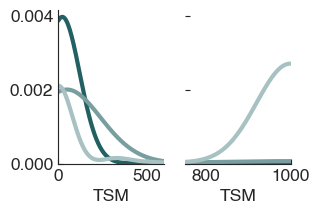

In [158]:
###density plot
def plot_density(df,col,ax,**kwargs):

    sns.kdeplot(df[col],ax=ax,clip=(0,1000), common_norm=False, **kwargs)

fig,axes= plt.subplots(1,2,figsize=(3,2),sharey=True) # 2 cols for broken axis
io_func.scale_rcparams(fig) 
for ax in axes :
    plot_density(df_plot_total_final,'TSM',ax,fill=False,color=palette[0],linewidth=3,label='TSM (P, M)',bw_adjust=3)
    plot_density(df_plot_total_hist,'TSM',ax,fill=False,color=palette[4],linewidth=3,label='TSM (P)',bw_adjust=3)
    plot_density(df_plot_total_hist,'SM',ax,fill=False,color=palette[1],linewidth=3,label='SM (P)',bw_adjust=0.5)
    # ax.set_yticks([])
    ax.set_ylabel('')

#zoom in on different parts
axes[0].set_xlim(0,600)
axes[1].set_xlim(750,1000)
axes[1].set_xticks([800,1000])
# hide the spines between ax and ax2
axes[1].spines['left'].set_visible(False)

# plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/fig2c_densityplots_fluxrange_3models.png',dpi=300,bbox_inches='tight')
# plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/fig2c_densityplots_fluxrange_3models.svg',dpi=300,bbox_inches='tight')


# box volumes

In [99]:
## box volume is the product of all flux ranges
from decimal import Decimal
def calc_box(df,column):
    return np.prod(df[column].values[df[column].values != 0])

def calc_box2(df, column):
    # Filter nonzero values
    non_zero_values = df[column].values[df[column].values != 0]
    # Use Decimal to compute the product
    product = Decimal(1)
    for value in non_zero_values:
        product *= Decimal(str(value))  # Convert to Decimal to avoid precision loss
    return product

##WT
print('wt',calc_box2(df_plot_tsm_WT,'TSM'),calc_box2(df_plot_tsm_WT,'SM'),calc_box2(df_plot_wt,'SM'))
##tm6
print('tm6',calc_box2(df_plot_tsm_TM6,'TSM'),calc_box2(df_plot_tsm_TM6,'SM'),calc_box2(df_plot_TM6,'SM'))

wt 5104852915350711320775.722196 9.817512172469779822681650379E+94 3.849139995783075591065740248E+481
tm6 3.988439327061418177898777817E+39 2.659190057195321102390568705E+80 5.070880627853868432957514510E+472


In [108]:
np.log( 5104852915350711320775.722196)

np.float64(49.98447859219615)

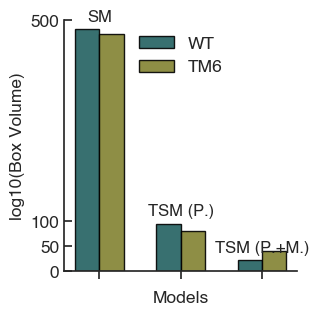

In [121]:
# 
##plot this as a bar plot
wt_values=[calc_box2(df_plot_tsm_WT,'TSM'),calc_box2(df_plot_tsm_WT,'SM'),calc_box2(df_plot_wt,'SM')]
# wt_values=[np.log10(i)  for i in reversed(wt_values)]
wt_values = [np.log10(i) for i in reversed(wt_values)]
tm6_values=[calc_box2(df_plot_tsm_TM6,'TSM'),calc_box2(df_plot_tsm_TM6,'SM'),calc_box2(df_plot_TM6,'SM')]
# tm6_values=[np.log10(i) for i in reversed(tm6_values)]
tm6_values = [np.log10(i) for i in reversed(tm6_values)]# wt_values=[i for i in reversed([1e-40,1e4,1e184])]

# Labels for the bars
labels = ['SM', 'TSM (P.)', 'TSM (P.+M.)']

# Bar positions
x = np.arange(len(labels))
width = 0.3  # Bar width
offset = width / 2  # Offset for slight separation

fig, ax = plt.subplots(figsize=(3.33, 3.33))

# Plotting WT and TM6
ax.bar(x - offset, wt_values, width,bottom=0, label='WT', color=sns.color_palette(palette)[0], alpha=0.9, edgecolor='black')
ax.bar(x + offset, tm6_values, width,bottom=0, label='TM6',  color=sns.color_palette(palette)[2], alpha=0.9, edgecolor='black')

# Setting the axes
# ax.set_yscale('log')  # Log scale for better visualization
ax.set_ylim(10,500)
# print(ax.get_yticks())
# ax.set_yticks([1e-50,1e-5,1e5,1e20,1e200])
# ax.set_yticklabels(['1e-50','1e-5','1e5','1e20','1e500'])
ax.set_ylabel('log10(Box Volume)')
##yticks
ax.set_yticks([0,50,100,500])
ax.set_xlabel('Models')
# ax.set_title('Comparison of Box Volume Reduction')
ax.set_xticks(x)
ax.set_xticklabels([])
ax.tick_params(axis='x', direction='out')
ax.legend(edgecolor='None',loc='upper center')
# ax.set_ylim(0, 600)
# Adding labels above the bars
for i, v in enumerate(wt_values):
    ax.text(x[i] , v + 10, f'{labels[i]}', ha='center', va='bottom', fontsize=12)

# Show plot
plt.tight_layout()
# # plt.locator_params(axis='y', nbins=4)
# plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/Fig2a_boxvols_onethird.png',dpi=300,bbox_inches='tight')
# plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/Fig2a_boxvols_onethird.svg',dpi=300,bbox_inches='tight')

## which flux ranges are reduced from tsm no met to tsm met

plot will be : 
- 2,1 subplot (WT,TM6)
- bar plots of flux ranges, for most reduced ranges from tsm no met to tsm met
- what is interesting is either flux ranges drastically reduced or flux range that become fully positive or negative

2nd version of plot : 
1 subplot, ~10 reactions, last model.  which reactions are constrained in one way for WT and the otheer for TM6

In [122]:
# fig,axes=plt.subplots(2,1,figsize=(8,8),layout='tight')
def plotbarplot(rxn_list,df_va,ax,offset=0,**kwargs):
        for i,rxn in enumerate(rxn_list):
            # ax.plot([df_va.loc[rxn,'lb']+visu_correct,df_va.loc[rxn,'ub']-visu_correct],[i+offset,i+offset],linewidth=1,solid_capstyle='projecting',**kwargs)
            width=df_va.loc[rxn,'ub']-df_va.loc[rxn,'lb']
            ax.barh(i+offset,width,left=df_va.loc[rxn,'lb'],height=0.4,edgecolor='black',**kwargs)

def plotbarplot2(rxn_list, df_va, ax, offset=0, capsize=5, **kwargs):
    for i, rxn in enumerate(rxn_list):
        lb = df_va.loc[rxn, 'lb']
        ub = df_va.loc[rxn, 'ub']
        center = (lb + ub) / 2
        half_range = (ub - lb) / 2

        # Plot a horizontal line with caps at both ends
        ax.errorbar(
            center, i + offset,
            xerr=half_range,
            fmt='none',               # No central marker
            ecolor=kwargs.get('color', 'black'),
            elinewidth=kwargs.get('linewidth', 1),
            capsize=capsize,
            capthick=kwargs.get('linewidth', 1),
        )
        
def reduced_range_plot(df_diff,df_va,cond,ax,rxn_count=5,offset=0,visu_correct=0,**kwargs):
    rxn_list=df_diff.sort_values('Relative difference',ascending=False).index[:rxn_count]
    df_va=df_va.loc[cond]
    #plot
    plotbarplot(rxn_list,df_va,ax,offset,**kwargs)
    ax.set_yticks(range(rxn_count))
    ax.set_yticklabels(rxn_list,fontsize=18)
    return rxn_list


# reduced_range_plot(df_plot_tsm_WT,VA_fluxes_fullmodel,'WT',axes[0],offset=0.3,color=sns.color_palette(palette)[0],alpha=0.5,label='WT, P.')
# rxn_wt=reduced_range_plot(df_plot_tsm_WT,VA_fluxes_fullmodel,'WT',axes[0],offset=-0,rxn_count=5,color=sns.color_palette(palette)[0],label='WT, P. + M.')
# axes[0].axvline(0, **cfg['settings_diagonal'])
# df_va_plot=VA_fluxes_fullmodel.loc['TM6']

# plotbarplot(rxn_wt,df_va_plot,axes[0],offset=-0.3,color=sns.color_palette(palette)[1])
# ##

# ##tm6
# reduced_range_plot(df_plot_tsm_TM6,VA_fluxes_fullmodel,'TM6',axes[1],offset=0.3,color=sns.color_palette(palette)[1],alpha=0.5,label='TM6, P.')
# rxn_tm6=reduced_range_plot(df_plot_tsm_TM6,VA_fluxes_fullmodel,'TM6',axes[1],offset=-0,rxn_count=5,color=sns.color_palette(palette)[1],label='TM6, P. + M.')
# axes[1].axvline(0, **cfg['settings_diagonal'])
# axes[0].set_xscale('symlog',linthresh=1.3),axes[1].set_xscale('symlog',linthresh=1.3)
# df_va_plot=VA_fluxes_fullmodel.loc['WT']
# plotbarplot(rxn_tm6,df_va_plot,axes[1],offset=-0.3,color=sns.color_palette(palette)[0])

# axes[0].set_xlim(-550,550),axes[1].set_xlim(-550,550)
# handles0,labels0=axes[0].get_legend_handles_labels()
# handles1,labels1=axes[1].get_legend_handles_labels()
# ##get unique labels ## very convenient from stack ov.
# handles=handles0+handles1
# labels=labels0+labels1
# unique=[(h,l) for i ,(h,l) in enumerate(zip(handles,labels)) if l not in labels[:i]]
# axes[1].legend(*zip(*unique),edgecolor='black',fontsize=18) ## dont forget to zip
# axes[1].set_xlabel('Flux bounds  $mmol\cdot (gDW\cdot h)^{-1}$ ')
# ##save figure
# plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/metandp_vs_ponly_5rxn.png',dpi=300,bbox_inches='tight')
# plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/metandp_vs_ponly_5rxn.svg',dpi=300,bbox_inches='tight')


In [142]:
# df_VA_fluxes_full# ## is the df of last model (with metabolome data)
## we take tm6 part and wt part and compare the ranges
## we take the difference between the ranges
##we take rxn with the highest difference
def get_diff_ranges(df_va,cond):
    df_va=df_va.loc[cond]
    diff_i=df_va['ub']-df_va['lb']
    return diff_i

ranges_TM6=get_diff_ranges(df_VA_fluxes_full,'TM6')
ranges_WT=get_diff_ranges(df_VA_fluxes_full,'WT')
normdiff_ranges=(ranges_TM6-ranges_WT)/ranges_WT
normdiff_ranges=normdiff_ranges.loc[[r.id for r in model.reactions if r not in model.boundary and len(r.compartments)==1 and 'reaction' not in r.id] ]
normdiff_ranges=normdiff_ranges.replace(np.nan,0)
normdiff_ranges=normdiff_ranges[normdiff_ranges!=0]
##round to 6
normdiff_ranges=normdiff_ranges.round(6)
a=normdiff_ranges.sort_values(ascending=False).tail(85)
## exclude transport rxn and boundary
rxn_list=normdiff_ranges.sort_values(ascending=False).head(5).index.append(a[~a.duplicated(keep='first')].index)
#drop SACCD2 and ampSYN1


In [143]:
rxn_list

Index(['gmpSYN2', 'G3PD2', 'NADH2-u6i', 'PPAm', 'ADK1m', 'GLU5K', 'dgmpSYN',
       'TKT2', 'RPE', 'TKT1', 'G6PDH2', 'TALA', 'PGI', 'TPI', 'FBA', 'GAPD',
       'PGK'],
      dtype='object')

In [154]:
rxn_list  # drop SACCD2 and ampSYN1
rxn_list = [rxn for rxn in rxn_list if rxn not in ['gmpSYN2', 'dgmpSYN']]
# rxn_list = list(reversed(['PDHm', 'G3PD1', 'GHMT2', 'FDH', 'ADK1m']))
rxn_list= list(reversed(['PYRDC','FDH','PGI','G3PD2','ATPS3m']))

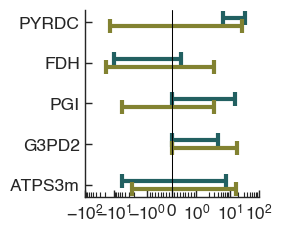

In [155]:
fig,axes=plt.subplots(1,1,figsize=(3,2.5),layout='tight')
io_func.scale_rcparams(fig,scalingf=0.5)
#because i divide figsize by 2 , also font size
# plt.rcParams['axes.linewidth']=1.25/2
# rxn_wt=reduced_range_plot(df_plot_final_WT,VA_fluxes_final,'WT',axes,offset=-0,rxn_count=5,color=sns.color_palette(palette)[0],label='WT, P. + M.')
df_va_plottm6=df_VA_fluxes_full.loc['TM6']
df_va_plotwt=df_VA_fluxes_full.loc['WT']

plotbarplot2(rxn_list,df_va_plotwt,axes,offset=0.1,color=sns.color_palette(palette)[0],label='WT',linewidth=3)
plotbarplot2(rxn_list,df_va_plottm6,axes,offset=-0.1,color=sns.color_palette(palette)[2],label='TM6',linewidth=3)
axes.axvline(0, color='black')
axes.set_yticks(range(len(rxn_list)))
axes.set_yticklabels(rxn_list)#,fontsize=25*2/3)
# axes.set_xticklabels(axes.get_xticklabels(),fontsize=25*2/3)


#x axis
axes.set_xscale('symlog',linthresh=1.3)
##set minor ticks on the symlog x axis
axes.tick_params(axis='x', which='minor', bottom=True)
axes.xaxis.set_minor_locator(io_func.MinorSymLogLocator(1e-1))
axes.set_xlim(-100,100)
handles,labels=axes.get_legend_handles_labels()
unique=[(h,l) for i ,(h,l) in enumerate(zip(handles,labels)) if l not in labels[:i]]
# axes.legend(*zip(*unique),edgecolor='None',) ## dont forget to zip

## save 
# plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/fig2d_fluxbounds_scale_errorbar.png',dpi=300,bbox_inches='tight')
# plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/fig2d_fluxbounds_scale_errorbar.svg',dpi=300,bbox_inches='tight')

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import Locator
### from stackoverflow
class MinorSymLogLocator(Locator):
    """
    Dynamically find minor tick positions based on the positions of
    major ticks for a symlog scaling.
    """
    def __init__(self, linthresh):
        """
        Ticks will be placed between the major ticks.
        The placement is linear for x between -linthresh and linthresh,
        otherwise its logarithmically
        """
        self.linthresh = linthresh

    def __call__(self):
        'Return the locations of the ticks'
        majorlocs = self.axis.get_majorticklocs()
        # add temporary major tick locs at either end of the current range
        # to fill in minor tick gaps
        dmlower = majorlocs[1] - majorlocs[0]    # major tick difference at lower end
        dmupper = majorlocs[-1] - majorlocs[-2]  # major tick difference at upper end

        # add temporary major tick location at the lower end
        if majorlocs[0] != 0. and ((majorlocs[0] != self.linthresh and dmlower > self.linthresh) or (dmlower == self.linthresh and majorlocs[0] < 0)):
            majorlocs = np.insert(majorlocs, 0, majorlocs[0]*10.)
        else:
            majorlocs = np.insert(majorlocs, 0, majorlocs[0]-self.linthresh)

        # add temporary major tick location at the upper end
        if majorlocs[-1] != 0. and ((np.abs(majorlocs[-1]) != self.linthresh and dmupper > self.linthresh) or (dmupper == self.linthresh and majorlocs[-1] > 0)):
            majorlocs = np.append(majorlocs, majorlocs[-1]*10.)
        else:
            majorlocs = np.append(majorlocs, majorlocs[-1]+self.linthresh)
            
        # iterate through minor locs
        minorlocs = []

        # handle the lowest part
        for i in range(1, len(majorlocs)):
            majorstep = majorlocs[i] - majorlocs[i-1]
            if abs(majorlocs[i-1] + majorstep/2) < self.linthresh:
                ndivs = 10
            else:
                ndivs = 9
            minorstep = majorstep / ndivs
            locs = np.arange(majorlocs[i-1], majorlocs[i], minorstep)[1:]
            minorlocs.extend(locs)

        return self.raise_if_exceeds(np.array(minorlocs))